# Task 3: Alternative Clustering Methods
We cluster MPs by how they vote with DBSCAN and Spectral Clustering, compare the result with Louvain and with the real parties, and check how sensitive and stable the clusters are.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

MIN_VOTES = 200         # minimum number of present votes (For/Against/Abstain) to keep an MP
DROP_UNANIMOUS = False  # drop sessions where one side has at least UNANIMOUS of the For/Against votes
UNANIMOUS = 0.95

: 

## 1. Load, encode and filter
We build an MP × session matrix with the encoding:

| Vote | Value |
|---|---|
| For | +1 |
| Against | −1 |
| Abstain | 0 |
| Absent | NaN (ignored) |

About 40% of all ballots are absences. In the Folketinget, absences are largely arranged between parties (*clearing*), so they say little about an MP's position, and we leave them out instead of treating them as a vote. Substitutes and MPs who joined or left during the period have few votes, so we keep only MPs with at least `MIN_VOTES` present votes. This filter is applied before the (optional) removal of near-unanimous sessions, so the set of MPs does not depend on `DROP_UNANIMOUS`.

An MP can belong to several parties over the period, so we label each MP with the party they voted for most often.

In [2]:
df = pd.read_csv("data/votes.csv", parse_dates=["date"])
assert not df.duplicated(["actor", "session"]).any()

X = (df.assign(vote=df["vote"].map({1: 1, 2: -1, 3: np.nan, 4: 0}))
       .pivot(index="actor", columns="session", values="vote"))

present = X.notna().sum(axis=1)
X = X[present >= MIN_VOTES]

if DROP_UNANIMOUS:
    yes_no = df[df["vote"].isin([1, 2])]
    majority = yes_no.groupby("session")["vote"].agg(lambda v: max((v == 1).mean(), (v == 2).mean()))
    X = X.drop(columns=majority[majority >= UNANIMOUS].index)

party = (df.dropna(subset=["party"])
           .groupby("actor")["party"]
           .agg(lambda p: p.value_counts().index[0])
           .reindex(X.index))

print(f"{len(X)} MPs (dropped {(present < MIN_VOTES).sum()}), {X.shape[1]} sessions")
party.value_counts()

181 MPs (dropped 54), 1302 sessions


party
Socialdemokratiet                                     52
Venstre, Danmarks Liberale Parti                      23
Socialistisk Folkeparti                               16
Moderaterne                                           15
Danmarksdemokraterne – Inger Støjberg                 15
Liberal Alliance                                      14
Det Konservative Folkeparti                           12
Enhedslisten                                          11
Dansk Folkeparti                                       7
Radikale Venstre                                       6
Alternativet                                           6
Uden for folketingsgrupperne - Lars Boje Mathiesen     1
Uden for folketingsgrupperne - Theresa Scavenius       1
Uden for folketingsgrupperne - Jon Stephensen          1
Uden for folketingsgrupperne - Mike Villa Fonseca      1
Name: count, dtype: int64

## 2. Agreement matrix
For every pair of MPs we count the sessions where both were present (`N`) and the share of those sessions where they voted the same way (`A`, the agreement rate). `D = 1 − A` is the distance used by DBSCAN, and `A` is the affinity used by Spectral Clustering and Louvain.

In [3]:
V = X.to_numpy()
M = (~np.isnan(V)).astype(float)

N = M @ M.T
agree = sum((V == k).astype(float) @ (V == k).T.astype(float) for k in (1, -1, 0))
with np.errstate(invalid="ignore", divide="ignore"):
    A = agree / N
D = 1 - A

print(A.shape, f"agreement rate: mean {np.nanmean(A):.3f}, min {np.nanmin(A):.3f}")

(181, 181) agreement rate: mean 0.748, min 0.000


### Pairs with few shared votes
The agreement rate of two MPs who rarely voted in the same session is unreliable (or undefined when `N = 0`), for example a substitute and the MP they replaced.

In [4]:
iu = np.triu_indices(len(X), k=1)
pairs = pd.DataFrame({
    "mp1":    X.index[iu[0]],
    "mp2":    X.index[iu[1]],
    "shared": N[iu].astype(int),
    "agree":  A[iu],
})
pairs["party1"] = pairs["mp1"].map(party)
pairs["party2"] = pairs["mp2"].map(party)

print(f"pairs: {len(pairs)}, with 0 shared votes: {(pairs['shared'] == 0).sum()}, "
      f"with < 30 shared votes: {(pairs['shared'] < 30).sum()}")
pairs[pairs["shared"] < 30].sort_values("shared")

pairs: 16290, with 0 shared votes: 129, with < 30 shared votes: 208


,mp1,mp2,shared,agree,party1,party2
5988,181,20925,0,NaN,Socialdemokratiet,Det Konservative Folkeparti
5989,181,20930,0,NaN,Socialdemokratiet,Socialdemokratiet
5990,181,20962,0,NaN,Socialdemokratiet,Socialistisk Folkeparti
5991,181,20966,0,NaN,Socialdemokratiet,Det Konservative Folkeparti
5993,181,21083,0,NaN,Socialdemokratiet,Socialdemokratiet
...,...,...,...,...,...,...
7762,238,20580,29,0.620690,Dansk Folkeparti,Moderaterne
6130,182,20841,29,0.655172,Danmarksdemokraterne – Inger Støjberg,Moderaterne
4193,134,20841,29,0.689655,Radikale Venstre,Moderaterne
14396,20354,20966,29,0.172414,Uden for folketingsgrupperne - Theresa Scavenius,Det Konservative Folkeparti


> **To decide:** how to treat these pairs (e.g. distance 1 / affinity 0, or a minimum overlap).

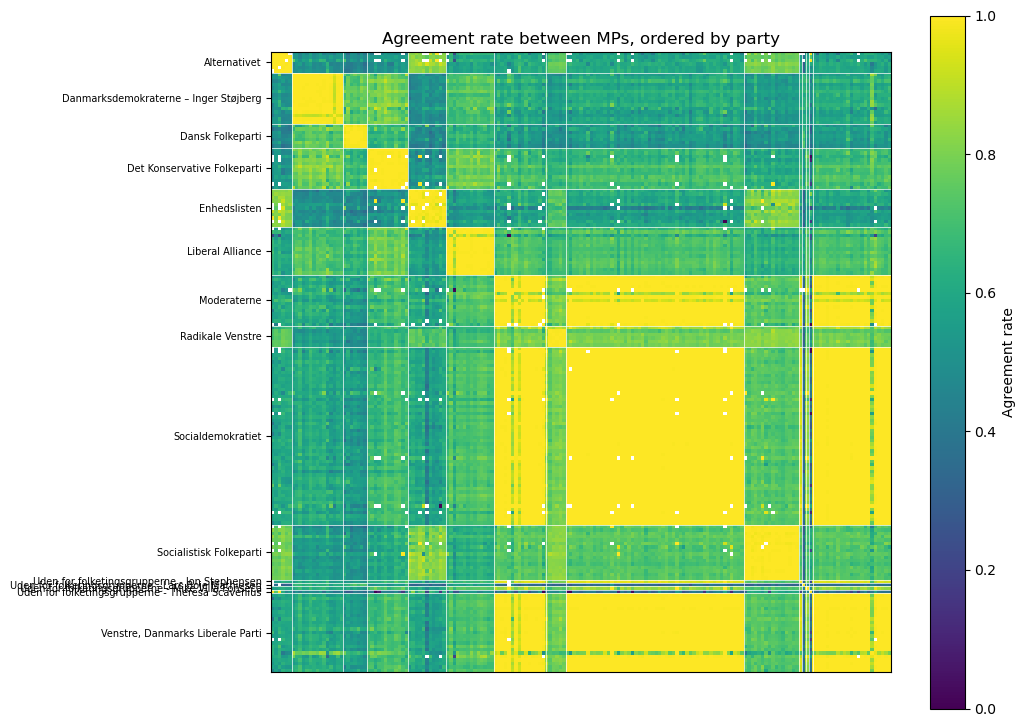

In [5]:
order = party.sort_values().index
idx = X.index.get_indexer(order)
labels = party[order].to_numpy()
bounds = np.flatnonzero(labels[1:] != labels[:-1]) + 0.5
centers = [np.flatnonzero(labels == p).mean() for p in pd.unique(labels)]

fig, ax = plt.subplots(figsize=(10, 9))
im = ax.imshow(A[np.ix_(idx, idx)], cmap="viridis")
for b in bounds:
    ax.axhline(b, color="white", lw=0.5)
    ax.axvline(b, color="white", lw=0.5)
ax.set_yticks(centers, pd.unique(labels), fontsize=7)
ax.set_xticks([])
ax.set_title("Agreement rate between MPs, ordered by party")
fig.colorbar(im, ax=ax, label="Agreement rate")
plt.show()